In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Main project folder
PROJECT = Path(
    "/content/drive/MyDrive/healthcare-analytics-capstone"
)

# Original datasets
RAW = PROJECT / "data" / "raw"

# Cleaned datasets
PROCESSED = PROJECT / "data" / "processed"

# Saved charts
IMAGES = PROJECT / "images"

# Reports and supporting outputs
REPORTS = PROJECT / "reports"

# Make sure the main folder exists
if not PROJECT.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {PROJECT}"
    )

if not RAW.is_dir():
    raise FileNotFoundError(
        f"Raw data folder not found: {RAW}"
    )

# Ensure output folders exist
PROCESSED.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT)
print("Raw data folder:", RAW)
print("Processed folder:", PROCESSED)
print("Images folder:", IMAGES)
print("Setup successful!")

Project folder: /content/drive/MyDrive/healthcare-analytics-capstone
Raw data folder: /content/drive/MyDrive/healthcare-analytics-capstone/data/raw
Processed folder: /content/drive/MyDrive/healthcare-analytics-capstone/data/processed
Images folder: /content/drive/MyDrive/healthcare-analytics-capstone/images
Setup successful!


In [ ]:
print("Files in my raw data folder:")

for file in sorted(RAW.iterdir()):
    print(file.name)

Files in my raw data folder:
ED_Waiting_Time_Data.xlsx
ICU_Sepsis_Patient_Data.xlsx
ICU_Sepsis_Patient_Data_Dictionary.xlsx
ICU_Sepsis_Patient_Summary.xlsx


In [ ]:
# Load the ED dataset
ed = pd.read_excel(
    RAW / "ED_Waiting_Time_Data.xlsx"
)

# Display the first five rows
ed.head()

,patient_id,visit_date,day_of_week,day_type,season,arrival_time,arrival_hour,department,triage_priority,chief_complaint,age,gender,staff_on_duty,patients_in_queue_at_arrival,registration_time_minutes,triage_time_minutes,wait_time_to_provider_minutes,consultation_duration_minutes,total_visit_duration_minutes
0,PT00001,2025-01-25,Saturday,Weekend,Harmattan/Dry,12:46:00,12,Maternity,4,Sprain,9,Male,9,6,4.3,9.1,46.8,12.9,73.1
1,PT00002,2025-07-09,Wednesday,Weekday,Peak Rainy,22:21:00,22,Maternity,4,Back pain,43,Male,8,3,4.4,9.8,33.1,9.1,56.4
2,PT00003,2025-06-02,Monday,Weekday,Peak Rainy,12:40:00,12,Maternity,4,Minor laceration,17,Male,12,3,6.1,8.9,25.6,11.2,51.8
3,PT00004,2025-05-17,Saturday,Weekend,Early Rainy,08:34:00,8,Emergency,4,Back pain,6,Male,10,4,7.7,7.4,47.2,17.0,79.3
4,PT00005,2025-09-05,Friday,Weekday,Peak Rainy,17:17:00,17,Outpatient - General,4,UTI symptoms,23,Female,11,2,7.0,6.6,56.4,18.0,88.0


In [ ]:
print("Number of rows:", ed.shape[0])
print("Number of columns:", ed.shape[1])

Number of rows: 6000
Number of columns: 19


In [ ]:
ed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   patient_id                     6000 non-null   object        
 1   visit_date                     6000 non-null   datetime64[ns]
 2   day_of_week                    6000 non-null   object        
 3   day_type                       6000 non-null   object        
 4   season                         6000 non-null   object        
 5   arrival_time                   6000 non-null   object        
 6   arrival_hour                   6000 non-null   int64         
 7   department                     6000 non-null   object        
 8   triage_priority                6000 non-null   int64         
 9   chief_complaint                5880 non-null   object        
 10  age                            6000 non-null   int64         
 11  gender           

In [ ]:
ed.describe(include="all")

,patient_id,visit_date,day_of_week,day_type,season,arrival_time,arrival_hour,department,triage_priority,chief_complaint,age,gender,staff_on_duty,patients_in_queue_at_arrival,registration_time_minutes,triage_time_minutes,wait_time_to_provider_minutes,consultation_duration_minutes,total_visit_duration_minutes
count,6000,6000,6000,6000,6000,6000,6000.00000,6000,6000.000000,5880,6000.000000,6000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
unique,6000,NaN,7,2,3,1237,NaN,5,NaN,23,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,PT00001,NaN,Monday,Weekday,Peak Rainy,19:49:00,NaN,Emergency,NaN,Back pain,NaN,Male,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,920,4351,2581,16,NaN,2087,NaN,437,NaN,3002,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2025-05-13 22:18:57.600000,NaN,NaN,NaN,NaN,13.43700,NaN,3.486000,NaN,33.718500,NaN,10.165333,5.270167,5.986750,8.065117,42.044583,14.867183,70.964050
min,NaN,2025-01-01 00:00:00,NaN,NaN,NaN,NaN,0.00000,NaN,1.000000,NaN,0.000000,NaN,3.000000,0.000000,1.000000,2.000000,0.000000,5.000000,15.100000
25%,NaN,2025-03-08 00:00:00,NaN,NaN,NaN,NaN,9.00000,NaN,3.000000,NaN,17.000000,NaN,9.000000,3.000000,4.600000,6.000000,25.700000,10.500000,54.600000
50%,NaN,2025-05-12 00:00:00,NaN,NaN,NaN,NaN,13.00000,NaN,4.000000,NaN,29.000000,NaN,11.000000,5.000000,6.000000,8.100000,42.600000,14.700000,71.150000
75%,NaN,2025-07-19 00:00:00,NaN,NaN,NaN,NaN,18.00000,NaN,4.000000,NaN,46.000000,NaN,12.000000,7.000000,7.300000,10.100000,58.900000,18.900000,87.200000
max,NaN,2025-09-27 00:00:00,NaN,NaN,NaN,NaN,23.00000,NaN,5.000000,NaN,95.000000,NaN,16.000000,20.000000,12.700000,19.000000,115.500000,40.000000,145.200000


In [ ]:
missing_values = ed.isnull().sum()

display(
    missing_values[missing_values > 0]
)

,0
chief_complaint,120


In [ ]:
print("Duplicate rows:", ed.duplicated().sum())

print(
    "Duplicate patient IDs:",
    ed["patient_id"].duplicated().sum()
)

Duplicate rows: 0
Duplicate patient IDs: 0


In [ ]:
print(
    "Negative waiting times:",
    (ed["wait_time_to_provider_minutes"] < 0).sum()
)

print(
    "Negative queue sizes:",
    (ed["patients_in_queue_at_arrival"] < 0).sum()
)

print(
    "Negative staffing values:",
    (ed["staff_on_duty"] < 0).sum()
)

print(
    "Unusual ages:",
    (~ed["age"].between(0, 120)).sum()
)

print(
    "Invalid arrival hours:",
    (~ed["arrival_hour"].between(0, 23)).sum()
)

Negative waiting times: 0
Negative queue sizes: 0
Negative staffing values: 0
Unusual ages: 0
Invalid arrival hours: 0


In [ ]:
# Keep original dataset unchanged
ed_clean = ed.copy()

# Convert visit_date to datetime
ed_clean["visit_date"] = pd.to_datetime(
    ed_clean["visit_date"],
    errors="coerce"
)

# Preserve missing chief complaint information
# as an explicit "Unknown" category
ed_clean["chief_complaint"] = (
    ed_clean["chief_complaint"].fillna("Unknown")
)

print("Processed rows:", len(ed_clean))
print("Unknown complaints:",
      (ed_clean["chief_complaint"] == "Unknown").sum())

print("Missing dates:",
      ed_clean["visit_date"].isna().sum())

Processed rows: 6000
Unknown complaints: 120
Missing dates: 0


In [ ]:
ed_clean.to_csv(
    PROCESSED / "ed_clean.csv",
    index=False
)

print("ED processed dataset saved successfully!")

ED processed dataset saved successfully!


In [ ]:
quality_report = pd.DataFrame({
    "column": ed.columns,
    "missing_count": ed.isna().sum().values,
    "data_type": ed.dtypes.astype(str).values
})

quality_report.to_csv(
    REPORTS / "ed_data_quality_summary.csv",
    index=False
)

display(quality_report)

,column,missing_count,data_type
0,patient_id,0,object
1,visit_date,0,datetime64[ns]
2,day_of_week,0,object
3,day_type,0,object
4,season,0,object
5,arrival_time,0,object
6,arrival_hour,0,int64
7,department,0,object
8,triage_priority,0,int64
9,chief_complaint,120,object


In [ ]:
wait = ed_clean["wait_time_to_provider_minutes"]

print("Total visits:", len(ed_clean))
print("Average wait:", round(wait.mean(), 2))
print("Median wait:", round(wait.median(), 2))
print("Minimum wait:", wait.min())
print("Maximum wait:", wait.max())
print("90th percentile:", round(wait.quantile(0.90), 2))

Total visits: 6000
Average wait: 42.04
Median wait: 42.6
Minimum wait: 0.0
Maximum wait: 115.5
90th percentile: 71.7


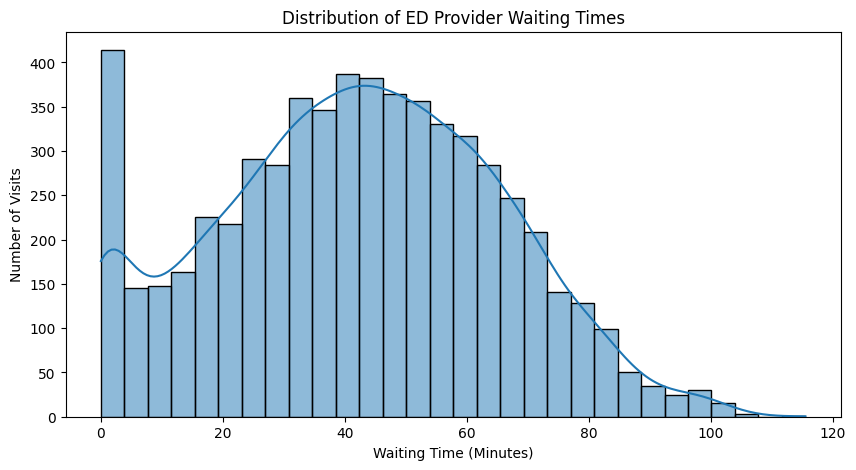

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=ed_clean,
    x="wait_time_to_provider_minutes",
    bins=30,
    kde=True
)

plt.title("Distribution of ED Provider Waiting Times")
plt.xlabel("Waiting Time (Minutes)")
plt.ylabel("Number of Visits")

plt.savefig(
    IMAGES / "ed_waiting_time_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
department_summary = (
    ed_clean.groupby("department")[
        "wait_time_to_provider_minutes"
    ]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

display(department_summary)

,count,mean,median
department,,,
Outpatient - General,1818,51.698405,53.0
Surgery Referral,629,46.601113,47.6
Pediatrics,871,40.254765,40.9
Emergency,2087,36.086536,36.4
Maternity,595,31.249076,31.3


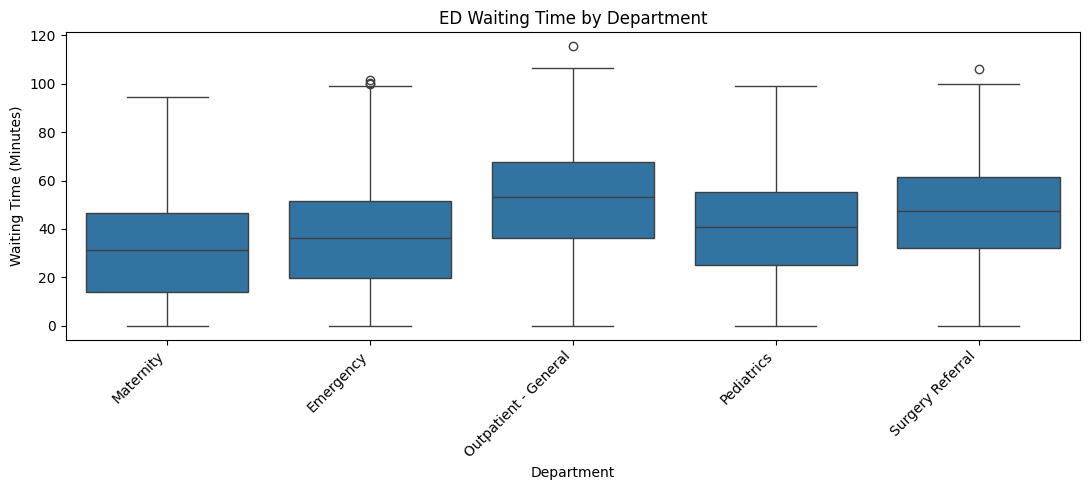

In [ ]:
plt.figure(figsize=(11, 5))

sns.boxplot(
    data=ed_clean,
    x="department",
    y="wait_time_to_provider_minutes"
)

plt.title("ED Waiting Time by Department")
plt.xlabel("Department")
plt.ylabel("Waiting Time (Minutes)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    IMAGES / "ed_wait_by_department.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

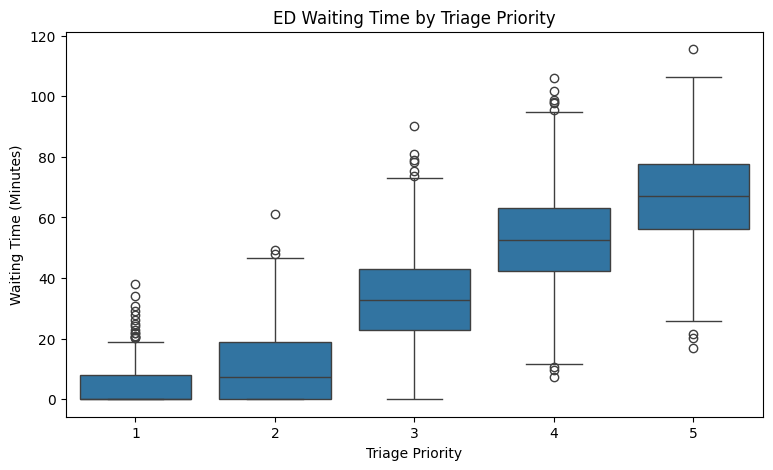

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=ed_clean,
    x="triage_priority",
    y="wait_time_to_provider_minutes"
)

plt.title("ED Waiting Time by Triage Priority")
plt.xlabel("Triage Priority")
plt.ylabel("Waiting Time (Minutes)")

plt.savefig(
    IMAGES / "ed_wait_by_triage.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

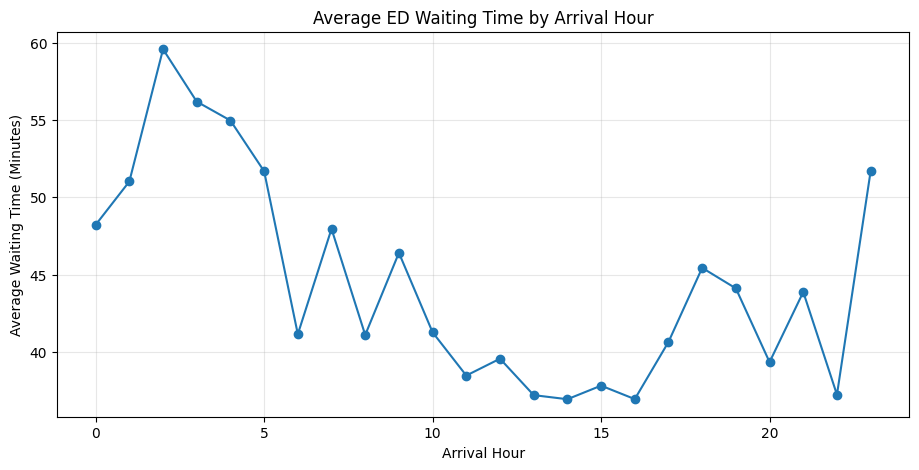

In [ ]:
hourly_wait = ed_clean.groupby(
    "arrival_hour"
)["wait_time_to_provider_minutes"].mean()

plt.figure(figsize=(11, 5))

hourly_wait.plot(kind="line", marker="o")

plt.title("Average ED Waiting Time by Arrival Hour")
plt.xlabel("Arrival Hour")
plt.ylabel("Average Waiting Time (Minutes)")
plt.grid(alpha=0.3)

plt.savefig(
    IMAGES / "ed_wait_by_hour.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

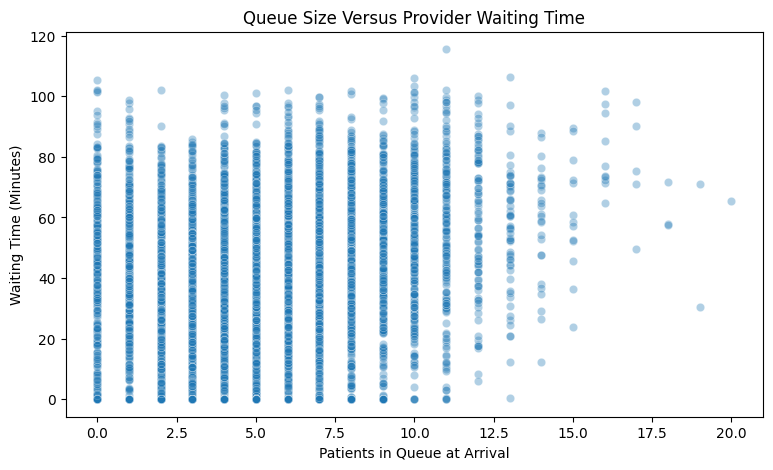

In [ ]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=ed_clean,
    x="patients_in_queue_at_arrival",
    y="wait_time_to_provider_minutes",
    alpha=0.35
)

plt.title("Queue Size Versus Provider Waiting Time")
plt.xlabel("Patients in Queue at Arrival")
plt.ylabel("Waiting Time (Minutes)")

plt.savefig(
    IMAGES / "ed_queue_vs_wait.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
correlations = ed_clean[
    [
        "patients_in_queue_at_arrival",
        "staff_on_duty",
        "wait_time_to_provider_minutes"
    ]
].corr()

display(correlations)

,patients_in_queue_at_arrival,staff_on_duty,wait_time_to_provider_minutes
patients_in_queue_at_arrival,1.000000,0.179747,0.203839
staff_on_duty,0.179747,1.000000,-0.283547
wait_time_to_provider_minutes,0.203839,-0.283547,1.000000


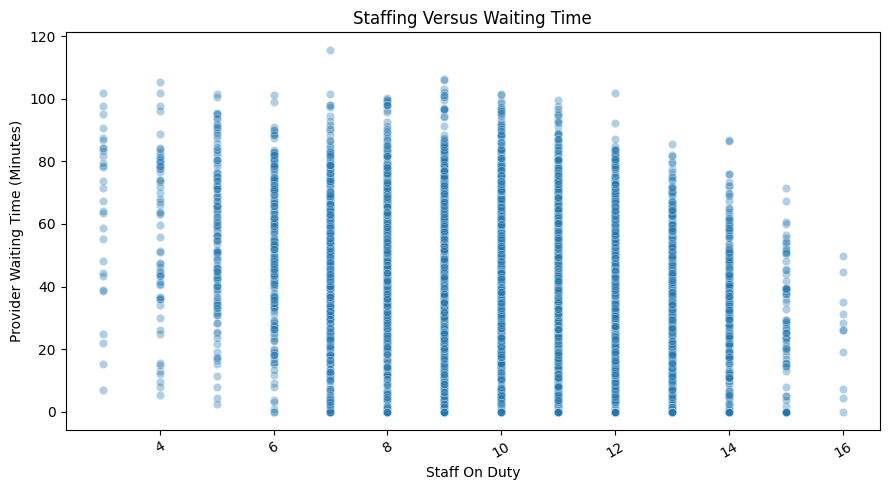

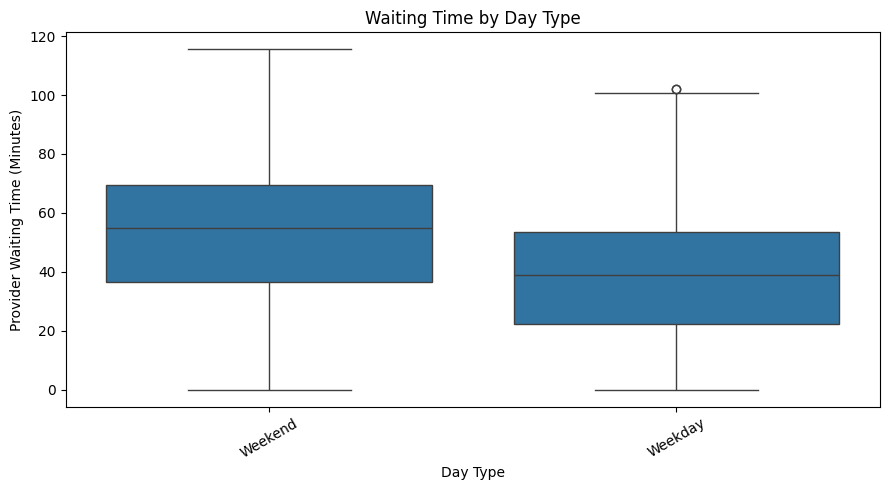

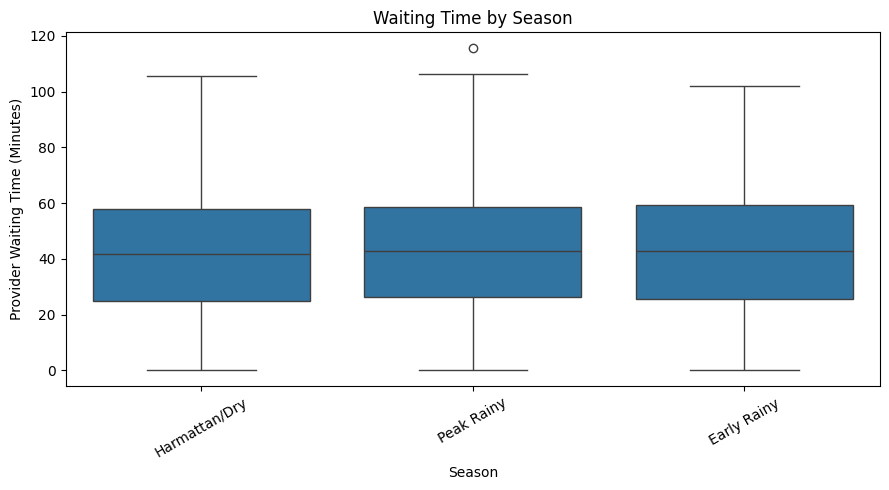

In [ ]:
charts = [
    ("staff_on_duty", "Staffing Versus Waiting Time",
     "ed_staffing_vs_wait.png"),

    ("day_type", "Waiting Time by Day Type",
     "ed_wait_by_day_type.png"),

    ("season", "Waiting Time by Season",
     "ed_wait_by_season.png")
]

for column, title, filename in charts:

    plt.figure(figsize=(9, 5))

    if column == "staff_on_duty":
        sns.scatterplot(
            data=ed_clean,
            x=column,
            y="wait_time_to_provider_minutes",
            alpha=0.35
        )
    else:
        sns.boxplot(
            data=ed_clean,
            x=column,
            y="wait_time_to_provider_minutes"
        )

    plt.title(title)
    plt.xlabel(column.replace("_", " ").title())
    plt.ylabel("Provider Waiting Time (Minutes)")
    plt.xticks(rotation=30)

    plt.tight_layout()

    plt.savefig(
        IMAGES / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

In [ ]:
multivariate_summary = ed_clean.pivot_table(
    index="department",
    columns="day_type",
    values="wait_time_to_provider_minutes",
    aggfunc="mean"
)

display(multivariate_summary)

day_type,Weekday,Weekend
department,,
Emergency,32.166820,46.645487
Maternity,28.376510,39.925000
Outpatient - General,47.222112,63.147554
Pediatrics,36.421160,50.751931
Surgery Referral,41.815332,57.493750


## Emergency Department Predictive Modeling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predictors available at arrival
numeric_features = [
    "patients_in_queue_at_arrival",
    "staff_on_duty",
    "arrival_hour"
]

categorical_features = [
    "department",
    "triage_priority",
    "day_type",
    "season"
]

features = numeric_features + categorical_features

target = "wait_time_to_provider_minutes"

# Do not impute the target or training dates
model_data = ed_clean.dropna(
    subset=[target, "visit_date"]
).copy()

print(
    "Records excluded because of missing targets/dates:",
    len(ed_clean) - len(model_data)
)

model_data["triage_priority"] = (
    model_data["triage_priority"].astype(str)
)

# Chronological split: earlier dates for training,
# later dates for testing
dates = sorted(
    model_data["visit_date"].dt.normalize().unique()
)

split_position = int(len(dates) * 0.8)
cutoff_date = dates[split_position]

train_data = model_data[
    model_data["visit_date"] < cutoff_date
]

test_data = model_data[
    model_data["visit_date"] >= cutoff_date
]

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Test period begins:", cutoff_date)

Records excluded because of missing targets/dates: 0
Training records: 4839
Testing records: 1161
Test period begins: 2025-08-05 00:00:00


In [ ]:
preprocessor = ColumnTransformer([
    (
        "numeric",
        SimpleImputer(strategy="median"),
        numeric_features
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=8,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions)
    })

ed_results = pd.DataFrame(results)

display(ed_results.round(3))

,Model,MAE,RMSE,R2
0,Linear Regression,7.269,9.147,0.842
1,Decision Tree,9.658,12.280,0.716
2,Random Forest,7.512,9.528,0.829


In [ ]:
ed_results.to_csv(
    PROCESSED / "ed_model_comparison.csv",
    index=False
)

print("ED model results saved!")

ED model results saved!
